In [1]:
from astropy import coordinates, units

# sh 2 71 PN coordinates
coord = coordinates.SkyCoord(ra=285.5, dec=2.156388, unit=units.degree)

In [29]:
from astroquery.gemini import Observations
from astropy.units import arcmin
from astropy.table import Table

width, height = 4.00 * arcmin, 4.00 * arcmin

all_obs = Observations.query_criteria(coordinates=coord, width=width, height=height, observation_class="science")

if all_obs is None or len(all_obs) == 0:
    raise ValueError("No observations found for the given coordinates.")

print(f"Found {len(all_obs)} observations for the given coordinates.")

print(f"Available columns: {all_obs.colnames}")

for filter in set(all_obs['filter_name']):
    filter_obs = all_obs[all_obs['filter_name'] == filter]
    print(f"Filter: {filter}, wl: {filter_obs[0]['wavelength_band']}, Number of observations: {len(filter_obs)}")


Found 52 observations for the given coordinates.
Available columns: ['exposure_time', 'detector_roi_setting', 'detector_welldepth_setting', 'telescope', 'mdready', 'requested_bg', 'engineering', 'cass_rotator_pa', 'ut_datetime', 'file_size', 'types', 'requested_wv', 'detector_readspeed_setting', 'size', 'laser_guide_star', 'observation_id', 'science_verification', 'raw_cc', 'filename', 'instrument', 'reduction', 'camera', 'ra', 'detector_binning', 'lastmod', 'wavelength_band', 'data_size', 'mode', 'raw_iq', 'airmass', 'elevation', 'data_label', 'requested_iq', 'object', 'requested_cc', 'program_id', 'file_md5', 'central_wavelength', 'raw_wv', 'compressed', 'filter_name', 'detector_gain_setting', 'path', 'observation_class', 'qa_state', 'observation_type', 'calibration_program', 'md5', 'adaptive_optics', 'name', 'focal_plane_mask', 'data_md5', 'raw_bg', 'disperser', 'wavefront_sensor', 'gcal_lamp', 'detector_readmode_setting', 'phot_standard', 'local_time', 'spectroscopy', 'azimuth', 'r

In [30]:
red_obs: Table  = Observations.query_criteria(coordinates=coord, filter="Ha", radius=width / 2)

if red_obs is None or len(red_obs) == 0:
    raise ValueError("No observations found for the given coordinates.")

green_obs: Table = Observations.query_criteria(coordinates=coord, filter="OIII", radius=width / 2)

if green_obs is None or len(green_obs) == 0:
    raise ValueError("No observations found for the given coordinates.")


blue_obs: Table  = Observations.query_criteria(coordinates=coord, filter="HeIIC", radius=width / 2)

if blue_obs is None or len(blue_obs) == 0:
    raise ValueError("No observations found for the given coordinates.")


In [31]:
# sort observations by exposure time in descending order and download fits files
red_obs.sort('exposure_time', reverse=True)
green_obs.sort('exposure_time', reverse=True)
blue_obs.sort('exposure_time', reverse=True)

Observations.get_file(red_obs[0]['filename'], download_dir='fitsdata')
Observations.get_file(green_obs[0]['filename'], download_dir='fitsdata')
Observations.get_file(blue_obs[0]['filename'], download_dir='fitsdata')

In [32]:
# now for each file we get the data
from astropy.io import fits
import os

red_hdul  = fits.open(os.path.join('fitsdata', str(red_obs[0]['filename'])))
blue_hdul = fits.open(os.path.join('fitsdata', str(blue_obs[0]['filename'])))
green_hdul = fits.open(os.path.join('fitsdata', str(green_obs[0]['filename'])))

In [35]:
print(f"Red HDU: {red_hdul.info()}")
print(f"Green HDU: {green_hdul.info()}")
print(f"Blue HDU: {blue_hdul.info()}")

Filename: fitsdata\N20220418S0007.fits.bz2
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     252   ()      
  1               -1 ImageHDU       324   (288, 2112)   int16 (rescales to uint16)   
  2               -1 ImageHDU       288   (288, 2112)   int16 (rescales to uint16)   
  3               -1 ImageHDU       252   (288, 2112)   int16 (rescales to uint16)   
  4               -1 ImageHDU       252   (288, 2112)   int16 (rescales to uint16)   
  5               -1 ImageHDU       216   (288, 2112)   int16 (rescales to uint16)   
  6               -1 ImageHDU       180   (288, 2112)   int16 (rescales to uint16)   
  7               -1 ImageHDU       180   (288, 2112)   int16 (rescales to uint16)   
  8               -1 ImageHDU       144   (288, 2112)   int16 (rescales to uint16)   
  9               -1 ImageHDU       108   (288, 2112)   int16 (rescales to uint16)   
 10               -1 ImageHDU       108   (288, 2112)   int16 (rescale

In [153]:
import numpy as np
import re


# ============================================================
# FITS HEADER PARSING
# ============================================================

def parse_section(section_str):
    """
    Parse a FITS section such as:

        [1:512,1:4224]

    into:

        ((1, 512), (1, 4224))
    """
    x1, x2, y1, y2 = map(
        int,
        re.findall(r'\d+', section_str)
    )

    return ((x1, x2), (y1, y2))


def parse_ccdsum(ccdsum_str):
    """
    Parse CCDSUM such as:

        "2 2"

    into:

        (2, 2)
    """
    return tuple(
        map(int, ccdsum_str.split())
    )


# ============================================================
# DETECTOR → MOSAIC COORDINATES
# ============================================================

def global_indexes(detsec, ccdsum):
    """
    Convert FITS DETSEC coordinates into NumPy mosaic
    coordinates.

    Returns:
        x_start
        x_end
        y_start
        y_end
        flip_x
        flip_y
    """

    (x1, x2), (y1, y2) = detsec

    bin_x, bin_y = ccdsum

    # DETSEC can be written backwards, e.g.
    # [512:1,1:4224]
    flip_x = x2 < x1
    flip_y = y2 < y1

    # FITS coordinates are 1-based.
    # NumPy coordinates are 0-based.

    x_start = (min(x1, x2) - 1) // bin_x
    x_end   = (max(x1, x2) - 1) // bin_x + 1

    y_start = (min(y1, y2) - 1) // bin_y
    y_end   = (max(y1, y2) - 1) // bin_y + 1

    return (
        x_start,
        x_end,
        y_start,
        y_end,
        flip_x,
        flip_y
    )


# ============================================================
# COMMON CANVAS SIZE
# ============================================================

def common_canvas_shape(hdul_list):
    """
    Calculate the common detector-coordinate canvas required
    to contain ALL extensions from ALL color channels.

    Returns:

        (height, width)

    Example:

        (2304, 3072)
    """

    max_x = 0
    max_y = 0

    for hdul in hdul_list:

        for ihdu in hdul[1:]:

            detsec = parse_section(
                ihdu.header["DETSEC"]
            )

            ccdsum = parse_ccdsum(
                ihdu.header["CCDSUM"]
            )

            (
                x1,
                x2,
                y1,
                y2,
                _,
                _
            ) = global_indexes(
                detsec,
                ccdsum
            )

            max_x = max(max_x, x2)
            max_y = max(max_y, y2)

    return max_y, max_x


# ============================================================
# BUILD ONE COLOR MOSAIC
# ============================================================

def build_mosaic(hdul, canvas_shape):
    """
    Build one independent 2D detector mosaic.

    Every color uses the SAME canvas_shape, so the resulting
    red, green and blue arrays can be stacked directly.

    No normalization or resizing is performed here.
    """

    height, width = canvas_shape

    # NaN represents regions where this particular color
    # has no detector data.
    mosaic = np.full(
        (height, width),
        np.nan,
        dtype=np.float32
    )

    for hdu_index, ihdu in enumerate(hdul[1:], start=1):

        # ----------------------------------------------------
        # DATASEC
        # ----------------------------------------------------

        datasec = parse_section(
            ihdu.header["DATASEC"]
        )

        data = ihdu.data[
            datasec[1][0] - 1 : datasec[1][1],
            datasec[0][0] - 1 : datasec[0][1]
        ]

        # Convert to float32 so NaN is supported and so that
        # later calibration/stretching is easier.
        data = data.astype(
            np.float32,
            copy=False
        )

        # ----------------------------------------------------
        # DETSEC + CCDSUM
        # ----------------------------------------------------

        detsec = parse_section(
            ihdu.header["DETSEC"]
        )

        ccdsum = parse_ccdsum(
            ihdu.header["CCDSUM"]
        )

        (
            x1,
            x2,
            y1,
            y2,
            flip_x,
            flip_y
        ) = global_indexes(
            detsec,
            ccdsum
        )

        # ----------------------------------------------------
        # ORIENTATION
        # ----------------------------------------------------

        if flip_x:
            data = data[:, ::-1]

        if flip_y:
            data = data[::-1, :]

        # ----------------------------------------------------
        # TARGET REGION
        # ----------------------------------------------------

        target = mosaic[
            y1:y2,
            x1:x2
        ]

        print(
            f"HDU {hdu_index}: "
            f"DATA={data.shape} "
            f"TARGET={target.shape} "
            f"X={x1}:{x2} "
            f"Y={y1}:{y2} "
            f"FLIP=({flip_x},{flip_y})"
        )

        # ----------------------------------------------------
        # VALIDATION
        # ----------------------------------------------------

        if target.shape != data.shape:

            raise ValueError(
                f"Shape mismatch in HDU {hdu_index}: "
                f"DATA={data.shape}, "
                f"TARGET={target.shape}, "
                f"DATASEC={ihdu.header['DATASEC']}, "
                f"DETSEC={ihdu.header['DETSEC']}, "
                f"CCDSUM={ihdu.header['CCDSUM']}"
            )

        # ----------------------------------------------------
        # INSERT INTO MOSAIC
        # ----------------------------------------------------

        mosaic[
            y1:y2,
            x1:x2
        ] = data

    return mosaic


# ============================================================
# 1. DETERMINE COMMON CANVAS
# ============================================================

canvas_shape = common_canvas_shape(
    [
        red_hdul,
        green_hdul,
        blue_hdul
    ]
)

print(
    f"\nCommon canvas shape: {canvas_shape}"
)


# ============================================================
# 2. BUILD INDEPENDENT COLOR MOSAICS
# ============================================================

print("\n================ RED ================")

red_2d = build_mosaic(
    red_hdul,
    canvas_shape
)

print("\n================ GREEN ================")

green_2d = build_mosaic(
    green_hdul,
    canvas_shape
)

print("\n================ BLUE ================")

blue_2d = build_mosaic(
    blue_hdul,
    canvas_shape
)


# ============================================================
# 3. VERIFY
# ============================================================

print("\nFinal mosaic shapes:")

print("Red:  ", red_2d.shape)
print("Green:", green_2d.shape)
print("Blue: ", blue_2d.shape)


if not (
    red_2d.shape
    == green_2d.shape
    == blue_2d.shape
):
    raise ValueError(
        "Color mosaics do not have identical shapes."
    )


# ============================================================
# 4. CREATE RGB CUBE
# ============================================================

rgb_image = np.stack(
    (
        red_2d,
        green_2d,
        blue_2d
    ),
    axis=-1
)

print(
    "\nRGB image shape:",
    rgb_image.shape
)


Common canvas shape: (2304, 3072)

================ RED ================
HDU 1: DATA=(2112, 256) TARGET=(2112, 256) X=0:256 Y=0:2112 FLIP=(False,False)
HDU 2: DATA=(2112, 256) TARGET=(2112, 256) X=256:512 Y=0:2112 FLIP=(False,False)
HDU 3: DATA=(2112, 256) TARGET=(2112, 256) X=512:768 Y=0:2112 FLIP=(False,False)
HDU 4: DATA=(2112, 256) TARGET=(2112, 256) X=768:1024 Y=0:2112 FLIP=(False,False)
HDU 5: DATA=(2112, 256) TARGET=(2112, 256) X=1024:1280 Y=0:2112 FLIP=(False,False)
HDU 6: DATA=(2112, 256) TARGET=(2112, 256) X=1280:1536 Y=0:2112 FLIP=(False,False)
HDU 7: DATA=(2112, 256) TARGET=(2112, 256) X=1536:1792 Y=0:2112 FLIP=(False,False)
HDU 8: DATA=(2112, 256) TARGET=(2112, 256) X=1792:2048 Y=0:2112 FLIP=(False,False)
HDU 9: DATA=(2112, 256) TARGET=(2112, 256) X=2048:2304 Y=0:2112 FLIP=(False,False)
HDU 10: DATA=(2112, 256) TARGET=(2112, 256) X=2304:2560 Y=0:2112 FLIP=(False,False)
HDU 11: DATA=(2112, 256) TARGET=(2112, 256) X=2560:2816 Y=0:2112 FLIP=(False,False)
HDU 12: DATA=(2112, 

Red norm avg: 0.0, min: 0, max: 0
Green norm avg: 0.6801770528157552, min: 0, max: 255
Blue norm avg: 0.0, min: 0, max: 0


C:\Users\juanx\AppData\Local\Temp\ipykernel_13740\417011860.py:7: RuntimeWarning: invalid value encountered in cast
  return channel_data.astype(np.uint8)


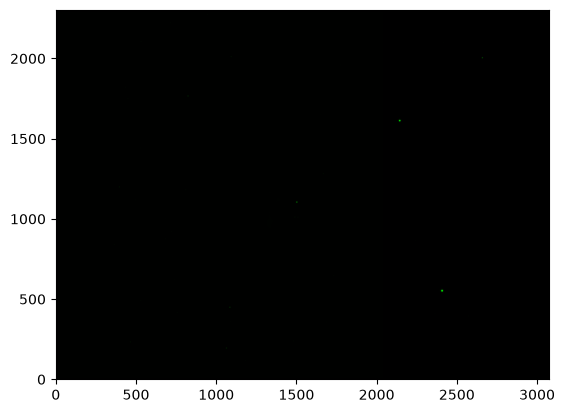

In [154]:
import matplotlib.pyplot as plt

def normalize_channel(channel_data: np.ndarray) -> np.ndarray:
    min_val = channel_data.min()
    max_val = channel_data.max()
    channel_data = (channel_data - min_val) / (max_val - min_val) * 255
    return channel_data.astype(np.uint8)   

red_norm = normalize_channel(red_2d)
green_norm = normalize_channel(green_2d)
blue_norm = normalize_channel(blue_2d)

print(f"Red norm avg: {np.mean(red_norm)}, min: {np.min(red_norm)}, max: {np.max(red_norm)}")
print(f"Green norm avg: {np.mean(green_norm)}, min: {np.min(green_norm)}, max: {np.max(green_norm)}")
print(f"Blue norm avg: {np.mean(blue_norm)}, min: {np.min(blue_norm)}, max: {np.max(blue_norm)}")

if red_norm.shape != green_norm.shape or red_norm.shape != blue_norm.shape:
    raise ValueError(f"The normalized channels do not have the same shape: red{red_norm.shape}, green{green_norm.shape}, blue{blue_norm.shape}")

rgb_image = np.stack((red_norm, green_norm, blue_norm), axis=-1)

plt.imshow(rgb_image, origin='lower')